# Accordo e confronto delle configurazioni di retrieval

Analisi della survey **Best-retrieval-results**, run **confronto-02**.

**Tutti gli score umani e le loro medie sono su scala 0–2:**
0 = non rilevante, 1 = parzialmente rilevante, 2 = rilevante.
La decodifica dei codici Qualtrics 1/2/3 usa le scelte effettive del QSF.
Alpha e Kendall sono indici statistici distinti dai voti umani e mantengono le scale standard.

Le domande condivise si contano una volta nell'accordo e si attribuiscono a tutte
le pipeline pertinenti per valutare il retrieval. Eseguibile dalla root o da `Qualtrics`.


In [1]:
from pathlib import Path
import sys
import importlib
import pandas as pd
from IPython.display import SVG, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'Qualtrics/analyze_retrieval.py').is_file())
sys.path.insert(0, str(ROOT / 'Qualtrics'))
import analyze_retrieval
importlib.reload(analyze_retrieval)
pd.set_option('display.precision', 3)
pd.set_option('display.max_colwidth', 90)
OUT = ROOT / 'Qualtrics/analysis'
analysis = analyze_retrieval.run_analysis(out_dir=OUT, bootstrap=10000, seed=20261103)
audit = analysis['audit']
print(f"Annotatori: {audit['n_annotators']} | Item: {audit['n_items']} | Query: {audit['n_queries']} | Etichette: {audit['n_labels']}")
print(f"Selezioni top-3: {audit['n_selections']} | Voti mancanti: {audit['n_missing_ratings']}")
annotations = pd.read_csv(OUT / 'annotations_long.csv')
assert annotations.relevance.between(0, 2).all()
print('Distribuzione score umani (0-2):')
print(annotations.relevance.value_counts().sort_index().rename_axis('Score umano').to_string())


Annotatori: 3 | Item: 101 | Query: 11 | Etichette: 11
Selezioni top-3: 132 | Voti mancanti: 0
Distribuzione score umani (0-2):
Score umano
0    112
1     69
2    122


## Accordo tra annotatori

**Alpha di Krippendorff ordinale** considera l'ordine 0 < 1 < 2, più annotatori
e voti mancanti. Si calcola prima di aggregare i voti. Gli IC al 95% sono bootstrap
degli item, condizionatamente agli annotatori osservati. La misura principale per
ogni coppia è ancora **alpha ordinale**, con IC bootstrap sui voti ricampionati insieme.
L'alpha globale non è la media degli alpha per coppia. Alpha nominale e kappa
quadratico per coppia restano diagnostiche aggiuntive; l'accordo esatto è una proporzione.
Un alpha negativo indica disaccordo maggiore di quello atteso per caso, non un voto umano negativo.


,n_items,n_ratings,alpha_ordinal,alpha_ci_low,alpha_ci_high,alpha_nominal,pairwise_exact_agreement,all_raters_exact_agreement,pairwise_extreme_disagreement
0,101,303,0.297,0.166,0.419,0.21,0.485,0.287,0.191


,annotator_a,annotator_b,n_items,alpha_ordinal,alpha_ci_low,alpha_ci_high,exact_agreement
0,ann_03ecaf62,ann_1fb83fbd,101,0.233,0.033,0.413,0.455
1,ann_03ecaf62,ann_948ed9de,101,0.221,0.026,0.403,0.455
2,ann_1fb83fbd,ann_948ed9de,101,0.401,0.218,0.565,0.545


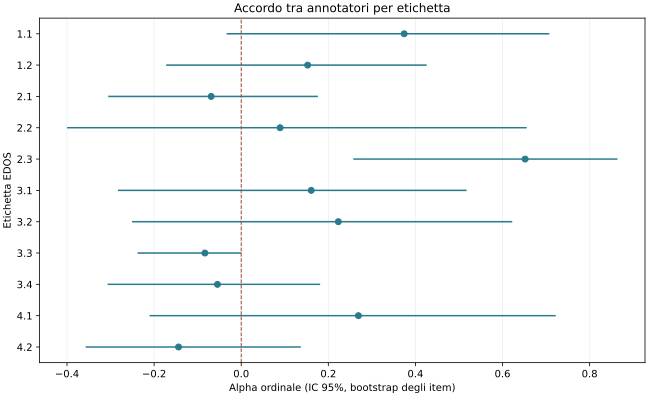

In [2]:
agreement = analysis['agreement']
display(agreement.loc[agreement.scope == 'global', [
    'n_items', 'n_ratings', 'alpha_ordinal', 'alpha_ci_low', 'alpha_ci_high',
    'alpha_nominal', 'pairwise_exact_agreement', 'all_raters_exact_agreement',
    'pairwise_extreme_disagreement']])
display(analysis['agreement_pairs'][[
    'annotator_a', 'annotator_b', 'n_items', 'alpha_ordinal',
    'alpha_ci_low', 'alpha_ci_high', 'exact_agreement']])
display(SVG(filename=str(OUT / 'agreement_by_label.svg')))


## Ranking delle configurazioni

La **rilevanza umana media (0–2)** misura la qualità dei tre passaggi senza considerare l'ordine.
**nDCG@3** considera anche la posizione: gain lineare e sconto `1/log2(rank+1)`.
Il denominatore ideale usa i migliori tre item del pool annotato della query,
uguale per tutti i sistemi. La variante esponenziale è un controllo di sensibilità.
Le metriche globali sono medie macro delle query; gli IC sono bootstrap delle query.


,rank_ndcg,rank_relevance,pipeline_id,Rilevanza umana media (0-2),Rilevanza IC95 inferiore (0-2),Rilevanza IC95 superiore (0-2),ndcg_pool_at3,ndcg_pool_at3_ci_low,ndcg_pool_at3_ci_high,ndcg_pool_at3_exponential
0,1,1,bge-m3__bge-reranker-v2-m3,1.141,0.919,1.333,0.759,0.670,0.850,0.701
3,2,2,qwen3-embedding-8b__qwen3-reranker-8b,1.071,0.758,1.364,0.677,0.526,0.805,0.621
1,3,3,bge-m3__qwen3-reranker-8b,1.000,0.707,1.283,0.616,0.513,0.728,0.548
2,4,4,qwen3-embedding-8b__bge-reranker-v2-m3,0.990,0.717,1.242,0.603,0.447,0.734,0.543


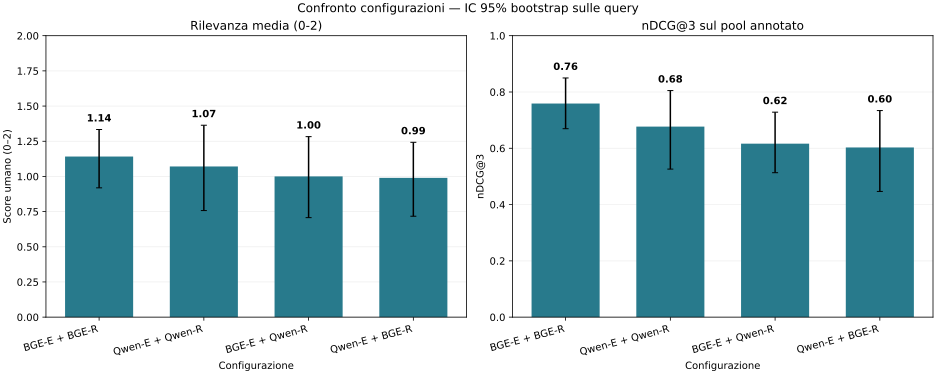

In [3]:
ranking = analysis['summary']
display(ranking[[
    'rank_ndcg', 'rank_relevance', 'pipeline_id', 'mean_relevance',
    'mean_relevance_ci_low', 'mean_relevance_ci_high', 'ndcg_pool_at3',
    'ndcg_pool_at3_ci_low', 'ndcg_pool_at3_ci_high', 'ndcg_pool_at3_exponential'
]].rename(columns={'mean_relevance': 'Rilevanza umana media (0-2)',
                   'mean_relevance_ci_low': 'Rilevanza IC95 inferiore (0-2)',
                   'mean_relevance_ci_high': 'Rilevanza IC95 superiore (0-2)'}))
display(SVG(filename=str(OUT / 'model_ranking.svg')))


## Chi ordina meglio in base agli score?

**nDCG@k** è la metrica classica per ranking con rilevanza graduata; qui `k=3`.
**Kendall tau-b** confronta direttamente l'ordine degli score del reranker con
quello dei giudizi umani e gestisce i pari merito. Score alto = rilevanza alta.
Si calcola per query, poi si media: non si concatenano score di query diverse.

- `kendall_tau_b_common`: usa gli **stessi item annotati**, presenti nei candidati di tutte le configurazioni.
- `kendall_tau_b_top3`: usa i tre item propri di ciascun sistema; le selezioni possono differire.
- `ndcg_order_at3`: ideale sui tre item propri, per studiare l'ordine condizionatamente alla selezione.

I valori non definiti restano mancanti e il numero di query valide è mostrato.
L'intersezione comune è un sottoinsieme del pool annotato: non è un test dell'intero ranking.
Un nDCG dell'ordine alto può coesistere con passaggi poco rilevanti o tutti con lo stesso giudizio.


In [4]:
display(ranking[[
    'pipeline_id', 'ndcg_order_at3', 'ndcg_order_at3_n',
    'kendall_tau_b_top3', 'kendall_tau_b_top3_n',
    'kendall_tau_b_common', 'kendall_tau_b_common_n',
    'kendall_tau_b_common_ci_low', 'kendall_tau_b_common_ci_high'
]])
common = pd.read_csv(OUT / 'ordering_common_pool.csv')
print('Item comuni:', common.groupby('query_id').n_common.first().sum())
display(common.pivot(index='edos_label', columns='pipeline_id', values='kendall_tau_b_common'))


Item comuni: 39


,pipeline_id,ndcg_order_at3,ndcg_order_at3_n,kendall_tau_b_top3,kendall_tau_b_top3_n,kendall_tau_b_common,kendall_tau_b_common_n,kendall_tau_b_common_ci_low,kendall_tau_b_common_ci_high
0,bge-m3__bge-reranker-v2-m3,0.942,11,0.018,10,0.266,9,-0.157,0.650
3,qwen3-embedding-8b__qwen3-reranker-8b,0.919,11,0.164,11,0.074,9,-0.363,0.512
1,bge-m3__qwen3-reranker-8b,0.916,11,0.331,9,0.059,9,-0.413,0.530
2,qwen3-embedding-8b__bge-reranker-v2-m3,0.904,10,0.037,10,0.266,9,-0.143,0.650


pipeline_id,bge-m3__bge-reranker-v2-m3,bge-m3__qwen3-reranker-8b,qwen3-embedding-8b__bge-reranker-v2-m3,qwen3-embedding-8b__qwen3-reranker-8b
edos_label,,,,
1.1 threats of harm,NaN,NaN,NaN,NaN
1.2 incitement and encouragement of harm,-0.333,-0.816,-0.333,-0.816
2.1 descriptive attacks,-0.816,0.816,-0.816,0.816
2.2 aggressive and emotive attacks,0.816,1.000,0.816,0.816
2.3 dehumanising attacks & overt sexual objectification,-0.333,1.000,-0.333,1.000
"3.1 casual use of gendered slurs, profanities, and insults",0.913,-0.400,0.913,0.000
3.2 immutable gender differences and gender stereotypes,0.800,-0.316,0.800,-0.400
3.3 backhanded gendered compliments,NaN,NaN,NaN,NaN
3.4 condescending explanations or unwelcome advice,0.816,0.000,0.816,0.000


## Pattern per etichetta EDOS

La heatmap confronta score umano medio su scala 0–2 e nDCG@3. La tabella mostra
accordo sugli item unici, rilevanza del pool e vincitori per etichetta, mantenendo i pari merito.
**Una sola query per etichetta:** le differenze sono descrittive.
Un nDCG alto può comparire anche in una categoria con passaggi quasi tutti irrilevanti:
va letto insieme allo score umano assoluto.


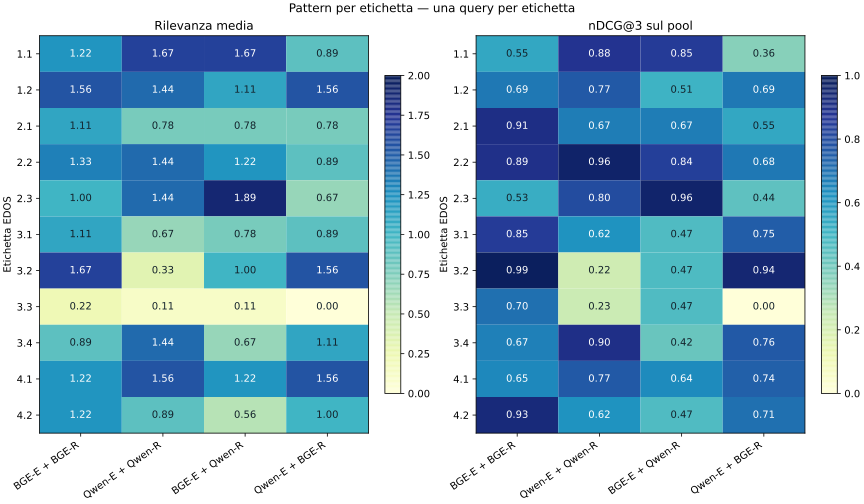

,edos_label,n_items,alpha_ordinal,alpha_ci_low,alpha_ci_high,Rilevanza umana media del pool (0-2),best_ndcg,best_relevance
0,1.1 threats of harm,11,0.374,-0.033,0.707,1.303,qwen3-embedding-8b__qwen3-reranker-8b,bge-m3__qwen3-reranker-8b; qwen3-embedding-8b__qwen3-reranker-8b
1,1.2 incitement and encouragement of harm,8,0.152,-0.172,0.426,1.625,qwen3-embedding-8b__qwen3-reranker-8b,bge-m3__bge-reranker-v2-m3; qwen3-embedding-8b__bge-reranker-v2-m3
2,2.1 descriptive attacks,10,-0.069,-0.305,0.176,0.833,bge-m3__bge-reranker-v2-m3,bge-m3__bge-reranker-v2-m3
3,2.2 aggressive and emotive attacks,6,0.089,-0.400,0.656,1.111,qwen3-embedding-8b__qwen3-reranker-8b,qwen3-embedding-8b__qwen3-reranker-8b
4,2.3 dehumanising attacks & overt sexual objectification,12,0.652,0.257,0.864,1.250,bge-m3__qwen3-reranker-8b,bge-m3__qwen3-reranker-8b
5,"3.1 casual use of gendered slurs, profanities, and insults",9,0.161,-0.283,0.517,0.852,bge-m3__bge-reranker-v2-m3,bge-m3__bge-reranker-v2-m3
6,3.2 immutable gender differences and gender stereotypes,8,0.223,-0.251,0.622,1.042,bge-m3__bge-reranker-v2-m3,bge-m3__bge-reranker-v2-m3
7,3.3 backhanded gendered compliments,9,-0.083,-0.238,0.000,0.111,bge-m3__bge-reranker-v2-m3,bge-m3__bge-reranker-v2-m3
8,3.4 condescending explanations or unwelcome advice,10,-0.055,-0.307,0.181,1.000,qwen3-embedding-8b__qwen3-reranker-8b,qwen3-embedding-8b__qwen3-reranker-8b
9,4.1 supporting mistreatment of individual women,8,0.269,-0.211,0.722,1.417,qwen3-embedding-8b__qwen3-reranker-8b,qwen3-embedding-8b__bge-reranker-v2-m3; qwen3-embedding-8b__qwen3-reranker-8b


In [5]:
display(SVG(filename=str(OUT / 'patterns_by_label.svg')))
display(analysis['label_patterns'][[
    'edos_label', 'n_items', 'alpha_ordinal', 'alpha_ci_low', 'alpha_ci_high',
    'pool_mean_relevance', 'best_ndcg', 'best_relevance'
]].rename(columns={'pool_mean_relevance': 'Rilevanza umana media del pool (0-2)'}))


## Stabilità del ranking e confronti appaiati

Confronto tra **media, mediana e soft label**. Le soft label sono le frequenze
dei voti sulle classi 0, 1 e 2. Il loro score umano `E[Y] = p1 + 2*p2` coincide
con la media: con gain lineare producono quindi gli stessi risultati.

Il confronto esponenziale usa `2^mean - 1` per la media, `2^median - 1` per la
mediana e **`E[2^Y - 1] = p1 + 3*p2` per le soft label**. Quest'ultima è una scelta
di utilità che conserva l'effetto della distribuzione, non una terza stima indipendente
dello score umano. Il gain è riscalato su 0–2 senza cambiare nDCG.
Si calcola nDCG dei gain attesi, non la media degli nDCG individuali.
Il gain esponenziale può favorire distribuzioni polarizzate a parità di media.

Lo score umano rimane sempre su **0–2**. Le tabelle riportano separatamente
il rank con gain lineare e quello con gain esponenziale; gli IC sono su query
e i ricampionamenti sono uguali tra le tre scelte di aggregazione.
Con la mediana l'etichetta 3.3 ha ideale tutto zero e nDCG non definito:
il confronto diretto di nDCG usa le **10 query valide comuni**. Gli score umani
usano tutte le 11 query. La prima tabella mantiene anche le medie su tutte le
query disponibili e ne mostra il numero per evitare confronti ambigui.
I test tra sistemi usano le stesse query, inversione esatta dei segni e correzione
di Holm: `p_holm` entro aggregazione e metrica, `p_holm_all_configs` su tutti
i confronti delle tre configurazioni. Gli IC dei delta sono bootstrap appaiati.
Con poche query e accordo basso il ranking resta esplorativo.


nDCG esponenziale sulle stesse query valide per tutte le aggregazioni:


,aggregation,pipeline_id,Score umano (0-2),rank_ndcg,ndcg_pool_at3,ndcg_pool_at3_n,rank_ndcg_exponential,ndcg_pool_at3_exponential,kendall_tau_b_common
0,mean,bge-m3__bge-reranker-v2-m3,1.141,1,0.759,11,1,0.701,0.266
1,mean,qwen3-embedding-8b__qwen3-reranker-8b,1.071,2,0.677,11,2,0.621,0.074
2,mean,bge-m3__qwen3-reranker-8b,1.000,3,0.616,11,3,0.548,0.059
3,mean,qwen3-embedding-8b__bge-reranker-v2-m3,0.990,4,0.603,11,4,0.543,0.266
4,median,bge-m3__bge-reranker-v2-m3,1.212,1,0.747,10,1,0.721,0.114
5,median,qwen3-embedding-8b__qwen3-reranker-8b,1.061,2,0.672,10,2,0.647,-0.013
6,median,qwen3-embedding-8b__bge-reranker-v2-m3,1.061,3,0.636,10,3,0.600,0.114
7,median,bge-m3__qwen3-reranker-8b,0.939,4,0.561,10,4,0.507,-0.068
8,soft,bge-m3__bge-reranker-v2-m3,1.141,1,0.759,11,1,0.740,0.266
9,soft,qwen3-embedding-8b__qwen3-reranker-8b,1.071,2,0.677,11,2,0.659,0.074


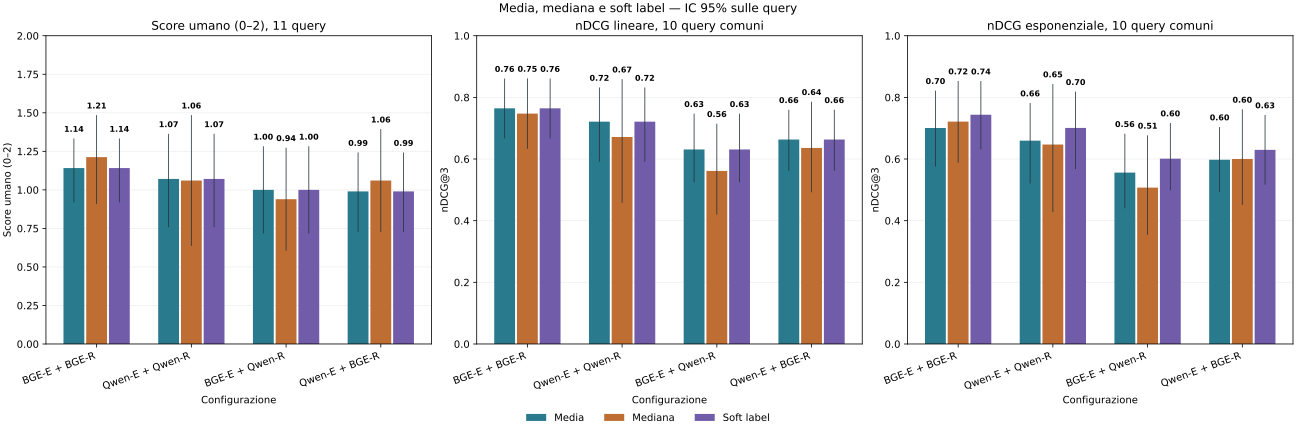

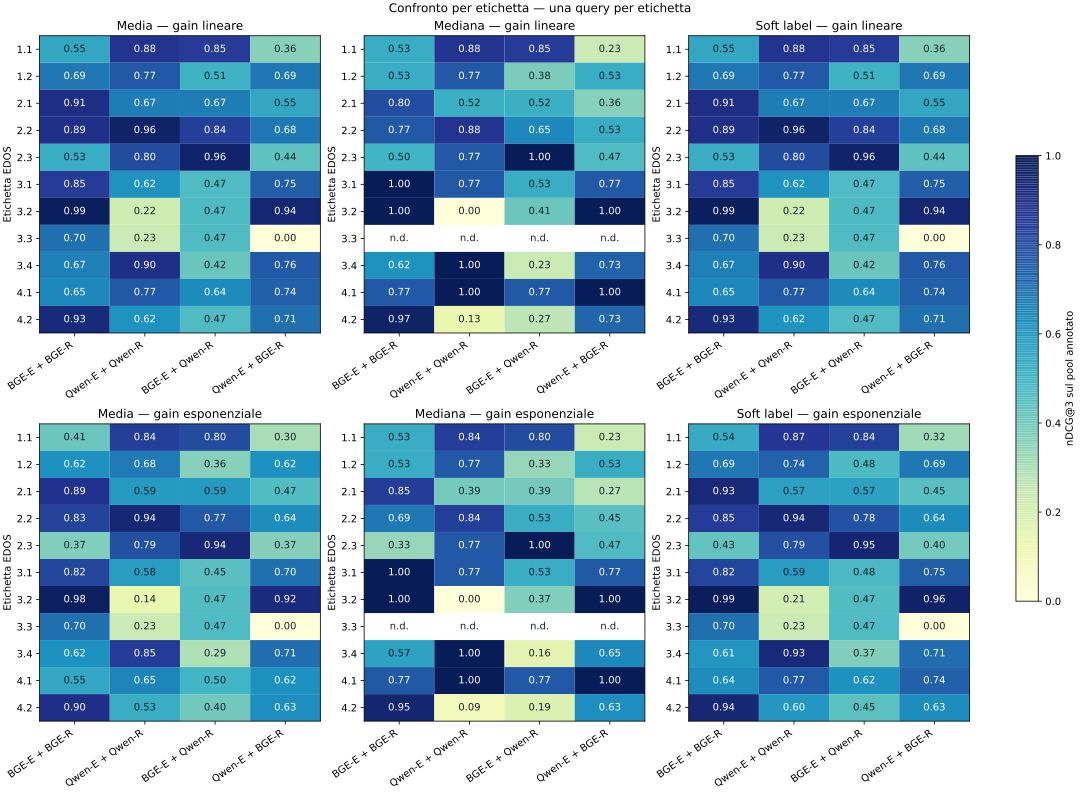

aggregation,mean,median,soft
pipeline_id,,,
bge-m3__bge-reranker-v2-m3,0.701,0.721,0.744
bge-m3__qwen3-reranker-8b,0.556,0.507,0.601
qwen3-embedding-8b__bge-reranker-v2-m3,0.598,0.600,0.630
qwen3-embedding-8b__qwen3-reranker-8b,0.660,0.647,0.701


,aggregation,pipeline_id,n_queries,rank_ndcg,ndcg_pool_at3,rank_ndcg_exponential,ndcg_pool_at3_exponential,ndcg_pool_at3_exponential_ci_low,ndcg_pool_at3_exponential_ci_high
0,mean,bge-m3__bge-reranker-v2-m3,10,1,0.765,1,0.701,0.576,0.822
1,mean,qwen3-embedding-8b__qwen3-reranker-8b,10,2,0.721,2,0.660,0.521,0.782
2,mean,qwen3-embedding-8b__bge-reranker-v2-m3,10,3,0.663,3,0.598,0.493,0.704
3,mean,bge-m3__qwen3-reranker-8b,10,4,0.631,4,0.556,0.440,0.682
4,median,bge-m3__bge-reranker-v2-m3,10,1,0.747,1,0.721,0.588,0.853
5,median,qwen3-embedding-8b__qwen3-reranker-8b,10,2,0.672,2,0.647,0.428,0.844
6,median,qwen3-embedding-8b__bge-reranker-v2-m3,10,3,0.636,3,0.600,0.451,0.761
7,median,bge-m3__qwen3-reranker-8b,10,4,0.561,4,0.507,0.354,0.677
8,soft,bge-m3__bge-reranker-v2-m3,10,1,0.765,1,0.744,0.631,0.853
9,soft,qwen3-embedding-8b__qwen3-reranker-8b,10,2,0.721,2,0.701,0.567,0.819


,pipeline_id,Rilevanza umana (0-2),ndcg_pool_at3,annotator,rank_ndcg
1,bge-m3__qwen3-reranker-8b,1.273,0.775,ann_03ecaf62,1
3,qwen3-embedding-8b__qwen3-reranker-8b,1.121,0.695,ann_03ecaf62,2
0,bge-m3__bge-reranker-v2-m3,0.970,0.624,ann_03ecaf62,3
2,qwen3-embedding-8b__bge-reranker-v2-m3,0.970,0.620,ann_03ecaf62,4
4,bge-m3__bge-reranker-v2-m3,0.970,0.552,ann_1fb83fbd,1
6,qwen3-embedding-8b__bge-reranker-v2-m3,0.879,0.489,ann_1fb83fbd,2
7,qwen3-embedding-8b__qwen3-reranker-8b,0.727,0.437,ann_1fb83fbd,3
5,bge-m3__qwen3-reranker-8b,0.576,0.296,ann_1fb83fbd,4
8,bge-m3__bge-reranker-v2-m3,1.485,0.795,ann_948ed9de,1
11,qwen3-embedding-8b__qwen3-reranker-8b,1.364,0.745,ann_948ed9de,2


,metric,pipeline_a,pipeline_b,delta_a_minus_b,delta_ci_low,delta_ci_high,wins_a,ties,wins_b,p_holm
0,ndcg_pool_at3,bge-m3__bge-reranker-v2-m3,bge-m3__qwen3-reranker-8b,0.143,-0.031,0.299,9,0,2,0.708
1,ndcg_pool_at3,bge-m3__bge-reranker-v2-m3,qwen3-embedding-8b__bge-reranker-v2-m3,0.156,0.040,0.294,8,1,2,0.176
2,ndcg_pool_at3,bge-m3__bge-reranker-v2-m3,qwen3-embedding-8b__qwen3-reranker-8b,0.082,-0.102,0.286,5,0,6,1.000
3,ndcg_pool_at3,bge-m3__qwen3-reranker-8b,qwen3-embedding-8b__bge-reranker-v2-m3,0.013,-0.182,0.216,5,0,6,1.000
4,ndcg_pool_at3,bge-m3__qwen3-reranker-8b,qwen3-embedding-8b__qwen3-reranker-8b,-0.061,-0.184,0.061,3,1,7,1.000
5,ndcg_pool_at3,qwen3-embedding-8b__bge-reranker-v2-m3,qwen3-embedding-8b__qwen3-reranker-8b,-0.074,-0.243,0.123,3,0,8,1.000
6,mean_relevance,bge-m3__bge-reranker-v2-m3,bge-m3__qwen3-reranker-8b,0.141,-0.141,0.374,8,1,2,1.000
7,mean_relevance,bge-m3__bge-reranker-v2-m3,qwen3-embedding-8b__bge-reranker-v2-m3,0.152,0.010,0.283,8,1,2,0.562
8,mean_relevance,bge-m3__bge-reranker-v2-m3,qwen3-embedding-8b__qwen3-reranker-8b,0.071,-0.212,0.394,6,0,5,1.000
9,mean_relevance,bge-m3__qwen3-reranker-8b,qwen3-embedding-8b__bge-reranker-v2-m3,0.010,-0.283,0.354,4,1,6,1.000


In [6]:
comparison = analysis['aggregation_comparison']
display(comparison[['aggregation', 'pipeline_id', 'mean_relevance', 'rank_ndcg',
                    'ndcg_pool_at3', 'ndcg_pool_at3_n', 'rank_ndcg_exponential', 'ndcg_pool_at3_exponential',
                    'kendall_tau_b_common']].rename(
    columns={'mean_relevance': 'Score umano (0-2)'}))
display(SVG(filename=str(OUT / 'aggregation_comparison.svg')))
display(SVG(filename=str(OUT / 'aggregation_patterns_by_label.svg')))
matched = analysis['aggregation_matched']
print('nDCG esponenziale sulle stesse query valide per tutte le aggregazioni:')
display(matched.pivot(index='pipeline_id', columns='aggregation',
                         values='ndcg_pool_at3_exponential'))
display(matched[['aggregation', 'pipeline_id', 'n_queries', 'rank_ndcg', 'ndcg_pool_at3',
                    'rank_ndcg_exponential', 'ndcg_pool_at3_exponential',
                    'ndcg_pool_at3_exponential_ci_low', 'ndcg_pool_at3_exponential_ci_high']])
display(pd.read_csv(OUT / 'annotator_model_ranking.csv').sort_values(
    ['annotator', 'rank_ndcg']).rename(columns={'mean_relevance': 'Rilevanza umana (0-2)'}))
display(analysis['paired'][[
    'metric', 'pipeline_a', 'pipeline_b', 'delta_a_minus_b',
    'delta_ci_low', 'delta_ci_high', 'wins_a', 'ties', 'wins_b', 'p_holm']])


## Lettura dei risultati

La sintesi seguente è ricalcolata dai dati. Tutti i voti umani sono su scala 0–2;
i delta tra sistemi sono differenze, che possono essere negative.


In [7]:
best = ranking.iloc[0]
global_agreement = agreement.loc[agreement.scope == 'global'].iloc[0]
labels = analysis['label_patterns']
highest_agreement = labels.sort_values('alpha_ordinal', ascending=False).iloc[0]
lowest_relevance = labels.sort_values('pool_mean_relevance').iloc[0]
print(f"Primo per nDCG: {best.pipeline_id}; nDCG@3 = {best.ndcg_pool_at3:.3f}; score umano = {best.mean_relevance:.3f}/2")
print(f"Alpha ordinale globale: {global_agreement.alpha_ordinal:.3f}, IC95 [{global_agreement.alpha_ci_low:.3f}, {global_agreement.alpha_ci_high:.3f}]")
print(f"Confronti significativi al 5% dopo Holm: {(analysis['paired'].p_holm < .05).sum()}")
print(f"Accordo più alto: {highest_agreement.edos_label}, alpha = {highest_agreement.alpha_ordinal:.3f}")
print(f"Pool meno rilevante: {lowest_relevance.edos_label}, score umano = {lowest_relevance.pool_mean_relevance:.3f}/2")


Primo per nDCG: bge-m3__bge-reranker-v2-m3; nDCG@3 = 0.759; score umano = 1.141/2
Alpha ordinale globale: 0.297, IC95 [0.166, 0.419]
Confronti significativi al 5% dopo Holm: 0
Accordo più alto: 2.3 dehumanising attacks & overt sexual objectification, alpha = 0.652
Pool meno rilevante: 3.3 backhanded gendered compliments, score umano = 0.111/2


## Metodo, limiti e riferimenti

Il pool contiene l'unione dei top-3: non permette recall sull'intero corpus né nDCG@10.
Passaggi e documenti riutilizzati creano dipendenze; gli IC su item/query sono approssimazioni.
Si confrontano pipeline embedding + reranker e l'inferenza condiziona sui tre annotatori osservati.
Il ranking non dimostra una superiorità generalizzabile dei singoli modelli.

- [Krippendorff, Computing Alpha-Reliability](https://www.asc.upenn.edu/sites/default/files/2021-03/Computing%20Krippendorff%27s%20Alpha-Reliability.pdf)
- [Järvelin e Kekäläinen, 2002, Cumulated Gain-based Evaluation of IR Techniques](https://researchportal.tuni.fi/en/publications/cumulated-gain-based-evaluation-of-ir-techniques/)
- [SciPy: Kendall tau-b e pari merito](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kendalltau.html)
- [Fornaciari et al. (2021): soft label come distribuzioni dei giudizi](https://aclanthology.org/2021.naacl-main.204/)

Report completo, audit e CSV: `analysis/`. Script: `analyze_retrieval.py`.
Seed 20261103, 10.000 repliche bootstrap. Test: `python -m unittest discover -s Qualtrics/tests -v` dalla root.
